<a href="https://colab.research.google.com/github/Karthi-x15/skin-disease-prediction/blob/main/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q kagglehub

In [ ]:
import kagglehub

# Download the dataset
path = kagglehub.dataset_download(
    "kmader/skin-cancer-mnist-ham10000"
)

print("Dataset path:", path)

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Dataset path: /kaggle/input/skin-cancer-mnist-ham10000


In [ ]:
import os

print(os.listdir(path))

['hmnist_8_8_RGB.csv', 'hmnist_28_28_RGB.csv', 'HAM10000_images_part_1', 'ham10000_images_part_1', 'hmnist_8_8_L.csv', 'HAM10000_images_part_2', 'ham10000_images_part_2', 'hmnist_28_28_L.csv', 'HAM10000_metadata.csv']


In [ ]:
import pandas as pd
import os

metadata_path = os.path.join(path, "HAM10000_metadata.csv")

df = pd.read_csv(metadata_path)

df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nDisease Distribution:")
print(df["dx"].value_counts())

Dataset Shape: (10015, 7)

Columns:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

Disease Distribution:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [ ]:
df.shape
df["dx"].value_counts()

,count
dx,
nv,6705
mel,1113
bkl,1099
bcc,514
akiec,327
vasc,142
df,115


In [ ]:
print(df.isnull().sum())

lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dtype: int64


In [ ]:
print(df["age"].describe())

count    9958.000000
mean       51.863828
std        16.968614
min         0.000000
25%        40.000000
50%        50.000000
75%        65.000000
max        85.000000
Name: age, dtype: float64


In [ ]:
print(df["sex"].value_counts())

sex
male       5406
female     4552
unknown      57
Name: count, dtype: int64


In [ ]:
print(df["localization"].value_counts())

localization
back               2192
lower extremity    2077
trunk              1404
upper extremity    1118
abdomen            1022
face                745
chest               407
foot                319
unknown             234
neck                168
scalp               128
hand                 90
ear                  56
genital              48
acral                 7
Name: count, dtype: int64


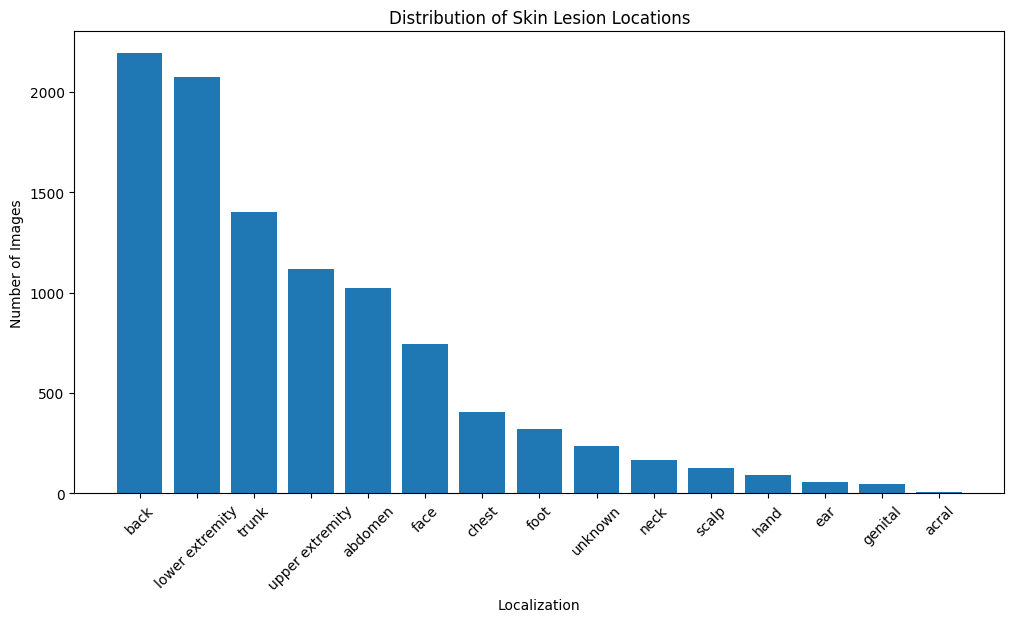

In [ ]:
import matplotlib.pyplot as plt

location_counts = df["localization"].value_counts()

plt.figure(figsize=(12, 6))

plt.bar(location_counts.index, location_counts.values)

plt.title("Distribution of Skin Lesion Locations")
plt.xlabel("Localization")
plt.ylabel("Number of Images")

plt.xticks(rotation=45)

plt.show()

In [ ]:
import os
import glob

# Get all image files from both folders
images_part1 = glob.glob(
    os.path.join(path, "HAM10000_images_part_1", "*.jpg")
)

images_part2 = glob.glob(
    os.path.join(path, "HAM10000_images_part_2", "*.jpg")
)

all_images = images_part1 + images_part2

print("Total images found:", len(all_images))
print("Total metadata records:", len(df))

Total images found: 10015
Total metadata records: 10015


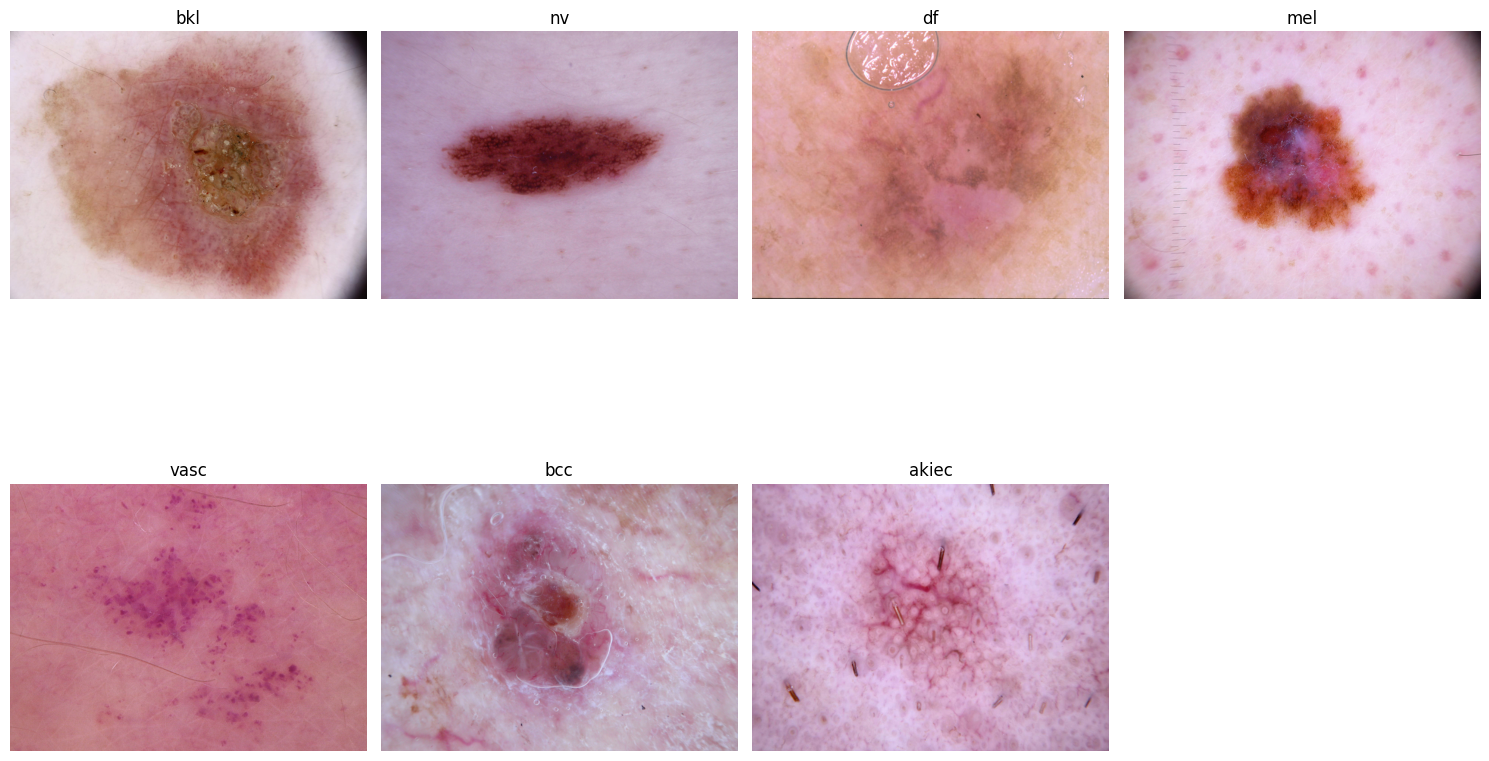

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random

# Disease categories
categories = df["dx"].unique()

plt.figure(figsize=(15, 10))

for i, category in enumerate(categories):

    # Select one random image from each category
    sample = df[df["dx"] == category].sample(1).iloc[0]

    image_id = sample["image_id"]

    # Find the image path
    image_path = None

    for img_path in all_images:
        if os.path.basename(img_path) == image_id + ".jpg":
            image_path = img_path
            break

    # Load image
    image = mpimg.imread(image_path)

    # Display
    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(category)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from PIL import Image
import random

# Select 10 random images
sample_images = random.sample(all_images, 10)

for image_path in sample_images:
    image = Image.open(image_path)
    print(
        os.path.basename(image_path),
        "→",
        image.size
    )

ISIC_0032684.jpg → (600, 450)
ISIC_0024871.jpg → (600, 450)
ISIC_0029023.jpg → (600, 450)
ISIC_0027433.jpg → (600, 450)
ISIC_0030499.jpg → (600, 450)
ISIC_0025676.jpg → (600, 450)
ISIC_0032896.jpg → (600, 450)
ISIC_0032062.jpg → (600, 450)
ISIC_0029460.jpg → (600, 450)
ISIC_0026256.jpg → (600, 450)


In [ ]:
# Create image_id -> image_path mapping

image_path_dict = {
    os.path.splitext(os.path.basename(img_path))[0]: img_path
    for img_path in all_images
}

print("Total images mapped:", len(image_path_dict))

Total images mapped: 10015


In [ ]:
df["image_path"] = df["image_id"].map(image_path_dict)

df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...


In [ ]:
print("Missing image paths:", df["image_path"].isnull().sum())

Missing image paths: 0


In [ ]:
len(image_path_dict)
df["image_path"].isnull().sum()

np.int64(0)

In [ ]:
from PIL import Image

corrupted_images = []

for index, image_path in enumerate(df["image_path"]):
    try:
        with Image.open(image_path) as img:
            img.verify()
    except Exception:
        corrupted_images.append(image_path)

print("Total corrupted images:", len(corrupted_images))

Total corrupted images: 0


In [ ]:
disease_mapping = {
    "akiec": "Actinic keratoses",
    "bcc": "Basal cell carcinoma",
    "bkl": "Benign keratosis-like lesions",
    "df": "Dermatofibroma",
    "mel": "Melanoma",
    "nv": "Melanocytic nevi",
    "vasc": "Vascular lesions"
}

df["disease_name"] = df["dx"].map(disease_mapping)

df[["image_id", "dx", "disease_name"]].head()

,image_id,dx,disease_name
0,ISIC_0027419,bkl,Benign keratosis-like lesions
1,ISIC_0025030,bkl,Benign keratosis-like lesions
2,ISIC_0026769,bkl,Benign keratosis-like lesions
3,ISIC_0025661,bkl,Benign keratosis-like lesions
4,ISIC_0031633,bkl,Benign keratosis-like lesions


In [ ]:
df["disease_name"].value_counts()

,count
disease_name,
Melanocytic nevi,6705
Melanoma,1113
Benign keratosis-like lesions,1099
Basal cell carcinoma,514
Actinic keratoses,327
Vascular lesions,142
Dermatofibroma,115


In [ ]:
df.to_csv("prepared_metadata.csv", index=False)

print("Prepared metadata saved successfully!")

Prepared metadata saved successfully!


In [ ]:
from google.colab import files

files.download("prepared_metadata.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,disease_name
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...,Benign keratosis-like lesions
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...,Benign keratosis-like lesions
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...,Benign keratosis-like lesions
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...,Benign keratosis-like lesions
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...,Benign keratosis-like lesions


In [ ]:
print("Total images:", len(df))
print("Unique lesions:", df["lesion_id"].nunique())

# Count lesions that have multiple images
lesion_counts = df["lesion_id"].value_counts()

multiple_images = lesion_counts[lesion_counts > 1]

print("Lesions with multiple images:", len(multiple_images))
print("Maximum images for one lesion:", lesion_counts.max())

Total images: 10015
Unique lesions: 7470
Lesions with multiple images: 1956
Maximum images for one lesion: 6


In [ ]:
duplicate_lesion_images = df[
    df["lesion_id"].isin(multiple_images.index)
]

print("Images belonging to lesions with multiple images:",
      len(duplicate_lesion_images))

Images belonging to lesions with multiple images: 4501


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# First split: 70% training and 30% temporary
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    gss.split(
        df,
        groups=df["lesion_id"]
    )
)

train_df = df.iloc[train_idx].copy()
temp_df = df.iloc[temp_idx].copy()

print("Training images:", len(train_df))
print("Temporary images:", len(temp_df))

Training images: 7002
Temporary images: 3013


In [ ]:
gss_temp = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    gss_temp.split(
        temp_df,
        groups=temp_df["lesion_id"]
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

Validation images: 1519
Testing images: 1494


In [ ]:
train_lesions = set(train_df["lesion_id"])
val_lesions = set(val_df["lesion_id"])
test_lesions = set(test_df["lesion_id"])

print(
    "Train-Val overlap:",
    len(train_lesions.intersection(val_lesions))
)

print(
    "Train-Test overlap:",
    len(train_lesions.intersection(test_lesions))
)

print(
    "Val-Test overlap:",
    len(val_lesions.intersection(test_lesions))
)

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [ ]:
print("TRAINING DATASET")
print(train_df["dx"].value_counts())

print("\nVALIDATION DATASET")
print(val_df["dx"].value_counts())

print("\nTESTING DATASET")
print(test_df["dx"].value_counts())

TRAINING DATASET
dx
nv       4718
mel       770
bkl       741
bcc       381
akiec     207
vasc       96
df         89
Name: count, dtype: int64

VALIDATION DATASET
dx
nv       991
bkl      206
mel      156
bcc       65
akiec     57
vasc      25
df        19
Name: count, dtype: int64

TESTING DATASET
dx
nv       996
mel      187
bkl      152
bcc       68
akiec     63
vasc      21
df         7
Name: count, dtype: int64


In [ ]:
all_classes = sorted(df["dx"].unique())

print("All classes:", all_classes)
print("Train classes:", sorted(train_df["dx"].unique()))
print("Validation classes:", sorted(val_df["dx"].unique()))
print("Test classes:", sorted(test_df["dx"].unique()))

All classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Train classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Validation classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Test classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


In [ ]:
label_mapping = {
    "akiec": 0,
    "bcc": 1,
    "bkl": 2,
    "df": 3,
    "mel": 4,
    "nv": 5,
    "vasc": 6
}

class_names = list(label_mapping.keys())

print(label_mapping)

{'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}


In [ ]:
for dataset in [train_df, val_df, test_df]:
    dataset["label"] = dataset["dx"].map(label_mapping)

print(train_df[["dx", "label"]].head())

    dx  label
0  bkl      2
1  bkl      2
2  bkl      2
3  bkl      2
4  bkl      2


In [ ]:
print("Training labels:")
print(train_df["label"].value_counts().sort_index())

Training labels:
label
0     207
1     381
2     741
3      89
4     770
5    4718
6      96
Name: count, dtype: int64


In [ ]:
train_df[["dx", "label"]].head()
train_df["label"].value_counts().sort_index()

,count
label,
0,207
1,381
2,741
3,89
4,770
5,4718
6,96


In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array(sorted(train_df["label"].unique()))

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"]
)

class_weights = dict(zip(classes, weights))

print("Class Weights:")
for label, weight in class_weights.items():
    print(f"Class {label} ({class_names[label]}): {weight:.2f}")

Class Weights:
Class 0 (akiec): 4.83
Class 1 (bcc): 2.63
Class 2 (bkl): 1.35
Class 3 (df): 11.24
Class 4 (mel): 1.30
Class 5 (nv): 0.21
Class 6 (vasc): 10.42


In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32

AUTOTUNE = tf.data.AUTOTUNE

In [ ]:
def load_image(image_path, label):
    # Read image
    image = tf.io.read_file(image_path)

    # Decode JPG
    image = tf.image.decode_jpeg(image, channels=3)

    # Resize image
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))

    # Normalize pixel values from 0-255 to 0-1
    image = image / 255.0

    return image, label

In [ ]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (
        train_df["image_path"].values,
        train_df["label"].values
    )
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (
        val_df["image_path"].values,
        val_df["label"].values
    )
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (
        test_df["image_path"].values,
        test_df["label"].values
    )
)

In [ ]:
train_ds = train_ds.map(
    load_image,
    num_parallel_calls=AUTOTUNE
)

val_ds = val_ds.map(
    load_image,
    num_parallel_calls=AUTOTUNE
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=AUTOTUNE
)

In [ ]:
train_ds = train_ds.shuffle(1000).batch(BATCH_SIZE).prefetch(AUTOTUNE)

val_ds = val_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

test_ds = test_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

In [ ]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Labels:", labels.numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Labels: [2 2 2 3 2 2 2 2 3 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 2 3 3 2 2]


In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

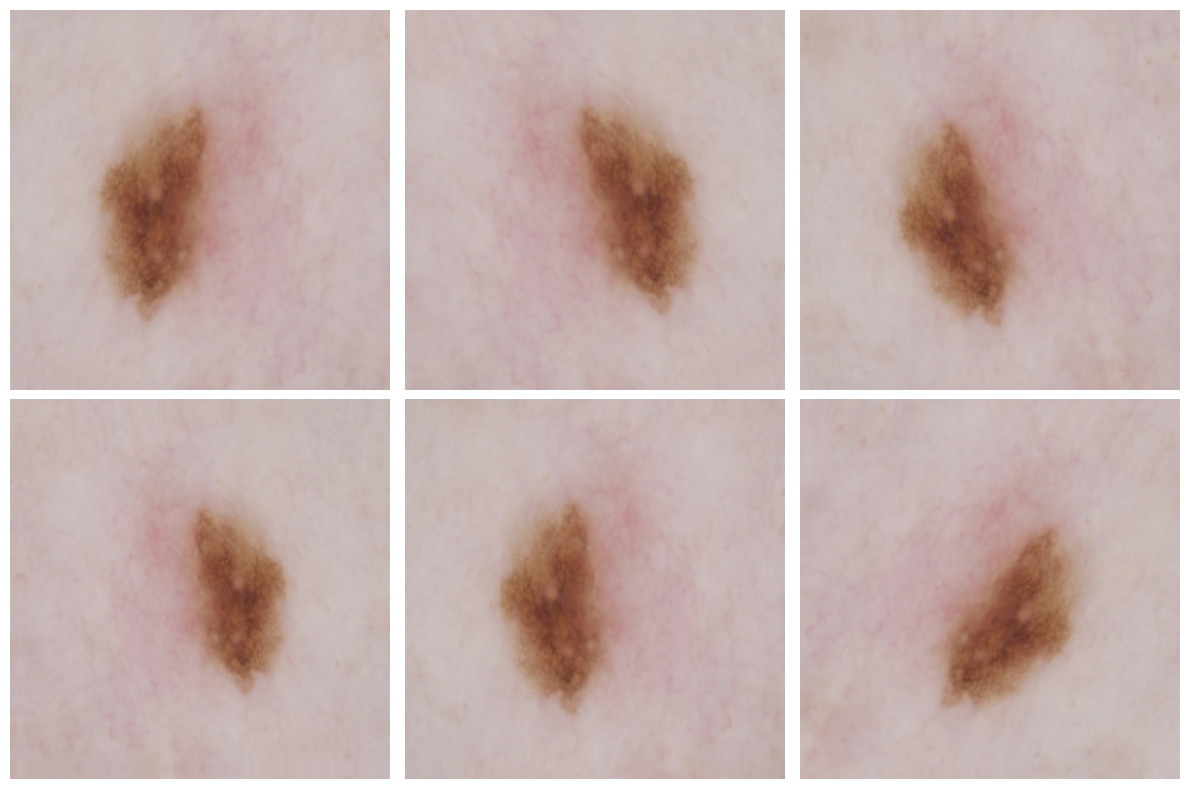

In [ ]:
import matplotlib.pyplot as plt

for images, labels in train_ds.take(1):

    plt.figure(figsize=(12, 8))

    for i in range(6):
        augmented_image = data_augmentation(
            tf.expand_dims(images[0], 0),
            training=True
        )

        plt.subplot(2, 3, i + 1)
        plt.imshow(augmented_image[0])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

    break

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
print("Built with CUDA:", tf.test.is_built_with_cuda())
print("GPU device:", tf.test.gpu_device_name())

Built with CUDA: True
GPU device: /device:GPU:0


In [ ]:
with tf.device("/GPU:0"):
    a = tf.random.normal([1000, 1000])
    b = tf.random.normal([1000, 1000])
    c = tf.matmul(a, b)

print("GPU test completed successfully!")

GPU test completed successfully!


In [ ]:
!pip install -q kagglehub

In [ ]:
import tensorflow as tf
import pandas as pd
import numpy as np
import os
import glob
import kagglehub

from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
path = kagglehub.dataset_download(
    "kmader/skin-cancer-mnist-ham10000"
)

print("Dataset path:", path)

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Dataset path: /kaggle/input/skin-cancer-mnist-ham10000


In [ ]:
metadata_path = os.path.join(path, "HAM10000_metadata.csv")

df = pd.read_csv(metadata_path)

print("Dataset shape:", df.shape)

Dataset shape: (10015, 7)


In [ ]:
images_part1 = glob.glob(
    os.path.join(path, "HAM10000_images_part_1", "*.jpg")
)

images_part2 = glob.glob(
    os.path.join(path, "HAM10000_images_part_2", "*.jpg")
)

all_images = images_part1 + images_part2

print("Total images found:", len(all_images))

Total images found: 10015


In [ ]:
image_path_dict = {
    os.path.splitext(os.path.basename(img_path))[0]: img_path
    for img_path in all_images
}

df["image_path"] = df["image_id"].map(image_path_dict)

print("Missing image paths:", df["image_path"].isnull().sum())

Missing image paths: 0


In [ ]:
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    gss.split(df, groups=df["lesion_id"])
)

train_df = df.iloc[train_idx].copy()
temp_df = df.iloc[temp_idx].copy()

print("Training images:", len(train_df))
print("Temporary images:", len(temp_df))

Training images: 7002
Temporary images: 3013


In [ ]:
gss_temp = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    gss_temp.split(
        temp_df,
        groups=temp_df["lesion_id"]
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 7002
Validation: 1519
Testing: 1494


In [ ]:
print(len(train_df), len(val_df), len(test_df))

7002 1519 1494


In [ ]:
label_mapping = {
    "akiec": 0,
    "bcc": 1,
    "bkl": 2,
    "df": 3,
    "mel": 4,
    "nv": 5,
    "vasc": 6
}

class_names = list(label_mapping.keys())

print(label_mapping)

{'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}


In [ ]:
for dataset in [train_df, val_df, test_df]:
    dataset["label"] = dataset["dx"].map(label_mapping)

print(train_df[["dx", "label"]].head())

    dx  label
0  bkl      2
1  bkl      2
2  bkl      2
3  bkl      2
4  bkl      2


In [ ]:
print(train_df["label"].value_counts().sort_index())

label
0     207
1     381
2     741
3      89
4     770
5    4718
6      96
Name: count, dtype: int64


In [ ]:
classes = np.array(sorted(train_df["label"].unique()))

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"]
)

class_weights = dict(zip(classes, weights))

print("Class Weights:")

for label, weight in class_weights.items():
    print(f"Class {label} ({class_names[label]}): {weight:.2f}")

Class Weights:
Class 0 (akiec): 4.83
Class 1 (bcc): 2.63
Class 2 (bkl): 1.35
Class 3 (df): 11.24
Class 4 (mel): 1.30
Class 5 (nv): 0.21
Class 6 (vasc): 10.42


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32

AUTOTUNE = tf.data.AUTOTUNE

In [ ]:
def load_image(image_path, label):
    # Read image file
    image = tf.io.read_file(image_path)

    # Decode JPEG image
    image = tf.image.decode_jpeg(image, channels=3)

    # Resize image
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))

    # Normalize pixel values
    image = image / 255.0

    return image, label

In [ ]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (
        train_df["image_path"].values,
        train_df["label"].values
    )
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (
        val_df["image_path"].values,
        val_df["label"].values
    )
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (
        test_df["image_path"].values,
        test_df["label"].values
    )
)

In [ ]:
train_ds = train_ds.map(
    load_image,
    num_parallel_calls=AUTOTUNE
)

val_ds = val_ds.map(
    load_image,
    num_parallel_calls=AUTOTUNE
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=AUTOTUNE
)

In [ ]:
train_ds = train_ds.shuffle(1000).batch(BATCH_SIZE).prefetch(AUTOTUNE)

val_ds = val_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

test_ds = test_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

In [ ]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Sample labels:", labels.numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Sample labels: [2 4 2 2 4 3 4 2 2 2 2 2 2 2 2 2 2 2 4 2 3 2 2 2 2 2 2 2 2 2 4 4]


In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
], name="data_augmentation")

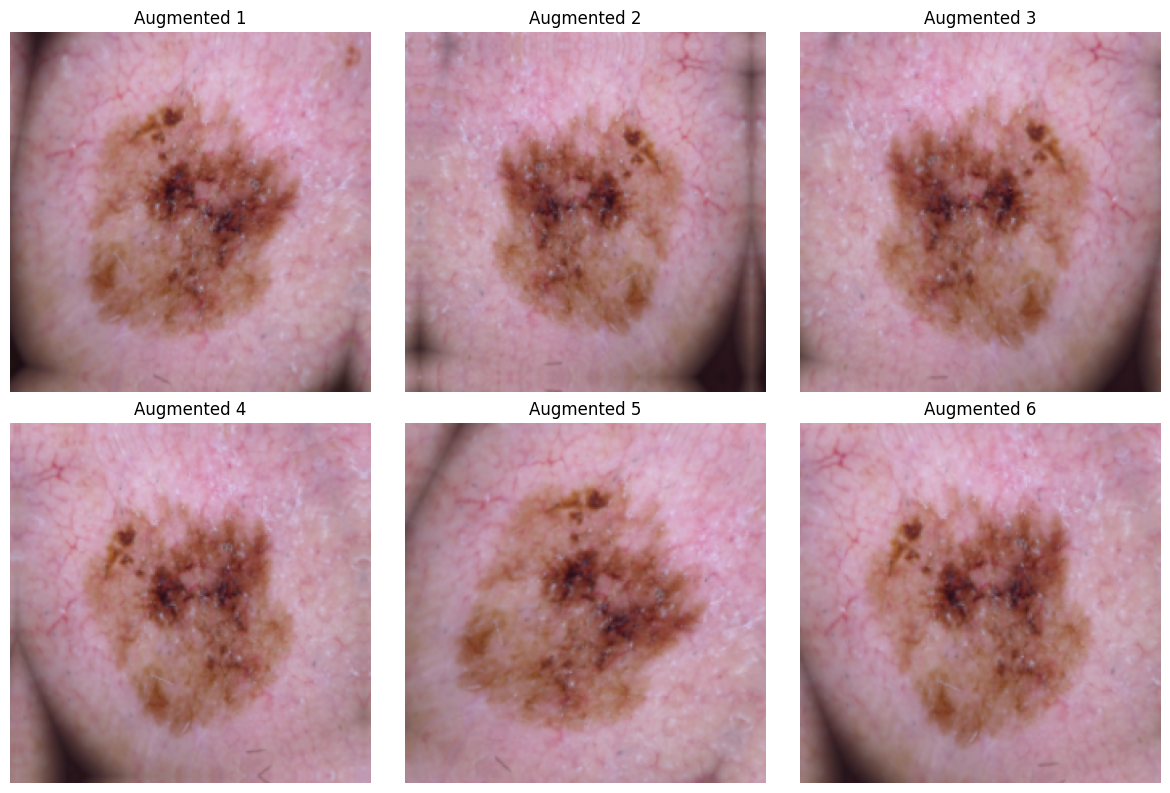

In [ ]:
import matplotlib.pyplot as plt

for images, labels in train_ds.take(1):

    plt.figure(figsize=(12, 8))

    for i in range(6):
        augmented_image = data_augmentation(
            tf.expand_dims(images[0], axis=0),
            training=True
        )

        plt.subplot(2, 3, i + 1)
        plt.imshow(augmented_image[0])
        plt.title(f"Augmented {i + 1}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

    break

In [ ]:
from tensorflow.keras.applications import EfficientNetB0

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Freeze the pre-trained layers initially
base_model.trainable = False

print("Base model loaded successfully!")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Base model loaded successfully!


In [ ]:
from tensorflow.keras import layers, models

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

# Data augmentation
x = data_augmentation(inputs)

# EfficientNetB0 base model
x = base_model(x, training=False)

# Convert feature maps into a feature vector
x = layers.GlobalAveragePooling2D()(x)

# Reduce overfitting
x = layers.Dropout(0.3)(x)

# Output layer for 7 skin disease classes
outputs = layers.Dense(
    7,
    activation="softmax"
)(x)

model = models.Model(inputs, outputs)

print("Model created successfully!")

Model created successfully!


In [ ]:
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,538 (15.48 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

callbacks = [
    # Stop training if validation loss stops improving
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    # Save the best model
    ModelCheckpoint(
        "best_skin_disease_model.keras",
        monitor="val_loss",
        save_best_only=True
    ),

    # Reduce learning rate if validation loss stops improving
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

print("Callbacks created successfully!")

Callbacks created successfully!


In [ ]:
def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)

    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))

    # DO NOT divide by 255 for EfficientNetB0
    image = tf.cast(image, tf.float32)

    return image, label

In [ ]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_df["image_path"].values, train_df["label"].values)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_df["image_path"].values, val_df["label"].values)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_df["image_path"].values, test_df["label"].values)
)

In [ ]:
train_ds = train_ds.map(
    load_image,
    num_parallel_calls=AUTOTUNE
)

val_ds = val_ds.map(
    load_image,
    num_parallel_calls=AUTOTUNE
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=AUTOTUNE
)

In [ ]:
train_ds = train_ds.shuffle(1000).batch(BATCH_SIZE).prefetch(AUTOTUNE)

val_ds = val_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

test_ds = test_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

In [ ]:
for images, labels in train_ds.take(1):
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Minimum pixel value: 0.0
Maximum pixel value: 255.0


In [ ]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models

# Load a fresh EfficientNetB0 model
base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Freeze pretrained layers
base_model.trainable = False


# Build the complete model
inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

# Data augmentation
x = data_augmentation(inputs)

# EfficientNetB0
x = base_model(x, training=False)

# Pooling
x = layers.GlobalAveragePooling2D()(x)

# Dropout
x = layers.Dropout(0.3)(x)

# Classification output
outputs = layers.Dense(
    7,
    activation="softmax"
)(x)

model = models.Model(inputs, outputs)

print("Fresh model created successfully!")

Fresh model created successfully!


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Fresh model compiled successfully!")

Fresh model compiled successfully!


In [ ]:
for images, labels in val_ds.take(1):
    predictions = model.predict(images, verbose=0)

    print("Images shape:", images.shape)
    print("Labels:", labels.numpy()[:10])

    predicted_classes = tf.argmax(predictions, axis=1)
    print("Predicted classes:", predicted_classes.numpy()[:10])

    print("Prediction probabilities for first image:")
    print(predictions[0])

Images shape: (32, 224, 224, 3)
Labels: [2 2 2 2 2 2 2 2 2 2]
Predicted classes: [2 2 0 4 4 2 2 2 2 4]
Prediction probabilities for first image:
[0.16195157 0.05280287 0.24100547 0.08734983 0.20429696 0.168587
 0.08400632]


In [ ]:
print("Sum of probabilities:", np.sum(predictions[0]))

Sum of probabilities: 1.0


In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 65s 219ms/step - accuracy: 0.6203 - loss: 1.6395 - val_accuracy: 0.2061 - val_loss: 2.7440 - learning_rate: 0.0010
Epoch 2/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 52s 213ms/step - accuracy: 0.6010 - loss: 1.6597 - val_accuracy: 0.3246 - val_loss: 2.2039 - learning_rate: 0.0010
Epoch 3/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 79s 192ms/step - accuracy: 0.6345 - loss: 1.4451 - val_accuracy: 0.4911 - val_loss: 1.8018 - learning_rate: 0.0010
Epoch 4/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 83s 208ms/step - accuracy: 0.6374 - loss: 1.3426 - val_accuracy: 0.5286 - val_loss: 1.7930 - learning_rate: 0.0010
Epoch 5/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 47s 193ms/step - accuracy: 0.6452 - loss: 1.2884 - val_accuracy: 0.5332 - val_loss: 1.7174 - learning_rate: 0.0010
Epoch 6/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 82s 191ms/step - accuracy: 0.6498 - loss: 1.2656 - val_accuracy: 0.5563 - val_loss: 1.6859 - learning_rate: 0.0010
Epoch 7/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 83s 197ms/step - accuracy: 0.6

In [ ]:
best_model = tf.keras.models.load_model(
    "best_skin_disease_model.keras"
)

val_loss, val_accuracy = best_model.evaluate(val_ds)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)

48/48 ━━━━━━━━━━━━━━━━━━━━ 12s 157ms/step - accuracy: 0.6248 - loss: 1.3763
Validation Loss: 1.3762623071670532
Validation Accuracy: 0.6247531175613403


In [ ]:
base_model.trainable = True

# Freeze the first layers and train only the later layers
fine_tune_at = 200

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

print("Total EfficientNet layers:", len(base_model.layers))
print("Fine-tuning started from layer:", fine_tune_at)

Total EfficientNet layers: 238
Fine-tuning started from layer: 200


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Model recompiled for fine-tuning!")

Model recompiled for fine-tuning!


In [ ]:
model.load_weights("best_skin_disease_model.keras")

print("Best Phase 1 weights loaded!")

Best Phase 1 weights loaded!


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 67s 211ms/step - accuracy: 0.2873 - loss: 1.4992 - val_accuracy: 0.5240 - val_loss: 1.3386 - learning_rate: 1.0000e-05
Epoch 2/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 49s 196ms/step - accuracy: 0.3103 - loss: 1.4059 - val_accuracy: 0.4865 - val_loss: 1.3956 - learning_rate: 1.0000e-05
Epoch 3/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 49s 200ms/step - accuracy: 0.3168 - loss: 1.3900 - val_accuracy: 0.4806 - val_loss: 1.3780 - learning_rate: 1.0000e-05
Epoch 4/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 84s 212ms/step - accuracy: 0.3406 - loss: 1.2719 - val_accuracy: 0.4898 - val_loss: 1.3490 - learning_rate: 5.0000e-06
Epoch 5/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 50s 207ms/step - accuracy: 0.3480 - loss: 1.2694 - val_accuracy: 0.4951 - val_loss: 1.3257 - learning_rate: 5.0000e-06
Epoch 6/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 48s 200ms/step - accuracy: 0.3546 - loss: 1.2486 - val_accuracy: 0.5049 - val_loss: 1.2980 - learning_rate: 5.0000e-06
Epoch 7/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 52s 21

In [ ]:
model.load_weights("best_skin_disease_model.keras")

In [ ]:
best_model = tf.keras.models.load_model(
    "best_skin_disease_model.keras"
)

val_loss, val_accuracy = best_model.evaluate(val_ds)

print("Best Model Validation Loss:", val_loss)
print("Best Model Validation Accuracy:", val_accuracy)

48/48 ━━━━━━━━━━━━━━━━━━━━ 12s 169ms/step - accuracy: 0.5214 - loss: 1.2385
Best Model Validation Loss: 1.2385411262512207
Best Model Validation Accuracy: 0.5213956832885742


In [ ]:
best_model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,177,882 (31.20 MB)

 Trainable params: 2,059,671 (7.86 MB)

 Non-trainable params: 1,998,867 (7.63 MB)

 Optimizer params: 4,119,344 (15.71 MB)

In [ ]:
for i, layer in enumerate(best_model.layers):
    print(i, layer.name, layer.trainable)

0 input_layer_5 True
1 data_augmentation True
2 efficientnetb0 True
3 global_average_pooling2d_1 True
4 dropout_1 True
5 dense_1 True


In [ ]:
base_model = best_model.get_layer("efficientnetb0")

print("EfficientNet trainable before:", base_model.trainable)
print("Total layers:", len(base_model.layers))

EfficientNet trainable before: True
Total layers: 238


In [ ]:
base_model.trainable = True

fine_tune_at = len(base_model.layers) - 30

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Fine-tuning starts at layer:", fine_tune_at)

Fine-tuning starts at layer: 208


In [ ]:
best_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Best model prepared for fine-tuning!")

Best model prepared for fine-tuning!


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

fine_tune_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        "best_fine_tuned_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-7,
        verbose=1
    )
]

print("Fine-tuning callbacks created successfully!")

Fine-tuning callbacks created successfully!


In [ ]:
fine_tune_history = best_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=fine_tune_callbacks
)

Epoch 1/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 0.5139 - loss: 1.6371
Epoch 1: val_loss improved from None to 0.91468, saving model to best_fine_tuned_model.keras

Epoch 1: finished saving model to best_fine_tuned_model.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 61s 204ms/step - accuracy: 0.5386 - loss: 1.0675 - val_accuracy: 0.6616 - val_loss: 0.9147 - learning_rate: 1.0000e-05
Epoch 2/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.5294 - loss: 1.7037
Epoch 2: val_loss improved from 0.91468 to 0.88367, saving model to best_fine_tuned_model.keras

Epoch 2: finished saving model to best_fine_tuned_model.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 48s 194ms/step - accuracy: 0.5800 - loss: 1.0603 - val_accuracy: 0.6702 - val_loss: 0.8837 - learning_rate: 1.0000e-05
Epoch 3/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step - accuracy: 0.5492 - loss: 1.7329
Epoch 3: val_loss did not improve from 0.88367

Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
2

In [ ]:
final_model = tf.keras.models.load_model(
    "best_fine_tuned_model.keras"
)

print("Best fine-tuned model loaded successfully!")

Best fine-tuned model loaded successfully!


In [ ]:
test_loss, test_accuracy = final_model.evaluate(test_ds)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

47/47 ━━━━━━━━━━━━━━━━━━━━ 12s 155ms/step - accuracy: 0.6975 - loss: 0.8420

Test Loss: 0.8419795036315918
Test Accuracy: 0.6974564790725708


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Get true labels
y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

# Get predictions
predictions = final_model.predict(test_ds)

y_pred = np.argmax(predictions, axis=1)

print("Total test samples:", len(y_true))
print("Total predictions:", len(y_pred))

47/47 ━━━━━━━━━━━━━━━━━━━━ 13s 222ms/step
Total test samples: 1494
Total predictions: 1494


In [ ]:
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

              precision    recall  f1-score   support

       akiec     0.2877    0.6667    0.4019        63
         bcc     0.4444    0.2353    0.3077        68
         bkl     0.5248    0.3487    0.4190       152
          df     0.1282    0.7143    0.2174         7
         mel     0.4074    0.4706    0.4367       187
          nv     0.9010    0.8223    0.8598       996
        vasc     0.4043    0.9048    0.5588        21

    accuracy                         0.6975      1494
   macro avg     0.4425    0.5947    0.4573      1494
weighted avg     0.7437    0.6975    0.7103      1494



<Figure size 1000x800 with 0 Axes>

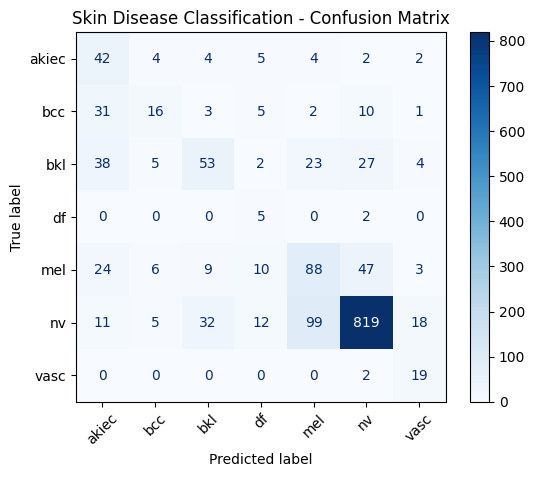

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Skin Disease Classification - Confusion Matrix")
plt.xticks(rotation=45)
plt.show()

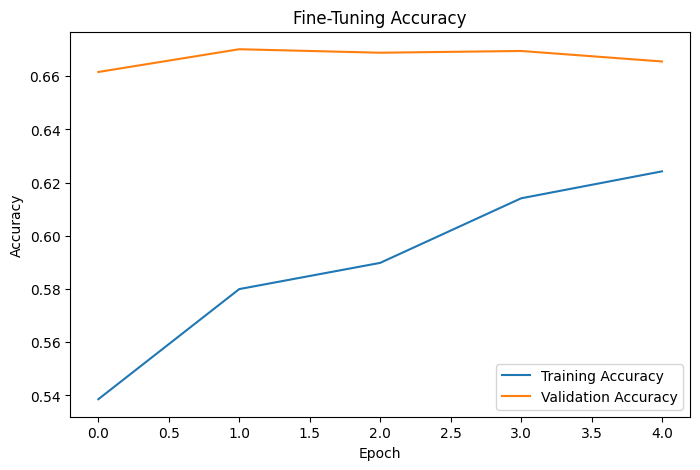

In [ ]:
import matplotlib.pyplot as plt

# Combine Phase 1 and fine-tuning histories later if needed.
# For now, plot fine-tuning history.

plt.figure(figsize=(8, 5))
plt.plot(fine_tune_history.history["accuracy"], label="Training Accuracy")
plt.plot(fine_tune_history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Fine-Tuning Accuracy")
plt.legend()
plt.show()

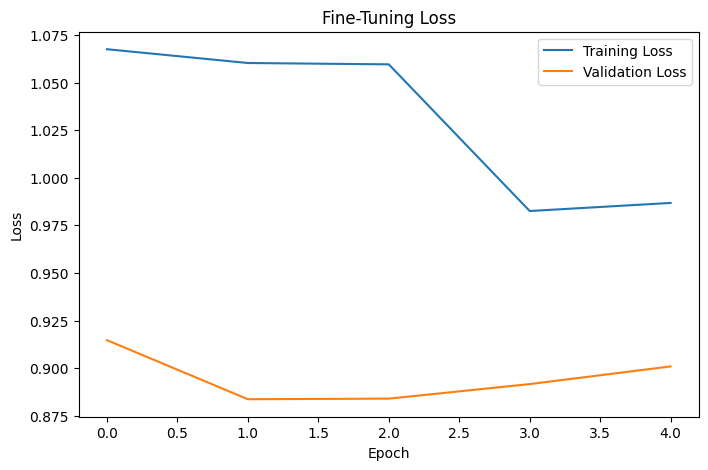

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(fine_tune_history.history["loss"], label="Training Loss")
plt.plot(fine_tune_history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Fine-Tuning Loss")
plt.legend()
plt.show()

In [ ]:
from collections import Counter

predicted_counts = Counter(y_pred)
actual_counts = Counter(y_true)

print("Actual class distribution:")
for label in range(7):
    print(
        f"{class_names[label]}: {actual_counts[label]}"
    )

print("\nPredicted class distribution:")
for label in range(7):
    print(
        f"{class_names[label]}: {predicted_counts[label]}"
    )

Actual class distribution:
akiec: 63
bcc: 68
bkl: 152
df: 7
mel: 187
nv: 996
vasc: 21

Predicted class distribution:
akiec: 146
bcc: 36
bkl: 101
df: 39
mel: 216
nv: 909
vasc: 47


In [ ]:
import numpy as np

# Convert existing class weights to moderated weights
improved_class_weights = {
    class_id: float(np.sqrt(weight))
    for class_id, weight in class_weights.items()
}

print("Original Class Weights:")
for class_id, weight in class_weights.items():
    print(f"{class_names[class_id]}: {weight:.2f}")

print("\nImproved Class Weights:")
for class_id, weight in improved_class_weights.items():
    print(f"{class_names[class_id]}: {weight:.2f}")

Original Class Weights:
akiec: 4.83
bcc: 2.63
bkl: 1.35
df: 11.24
mel: 1.30
nv: 0.21
vasc: 10.42

Improved Class Weights:
akiec: 2.20
bcc: 1.62
bkl: 1.16
df: 3.35
mel: 1.14
nv: 0.46
vasc: 3.23


In [ ]:
import os

print("Phase 1 model exists:", os.path.exists("best_skin_disease_model.keras"))
print("Fine-tuned model exists:", os.path.exists("best_fine_tuned_model.keras"))

Phase 1 model exists: True
Fine-tuned model exists: True


In [ ]:
experiment_model = tf.keras.models.load_model(
    "best_skin_disease_model.keras"
)

print("Experiment model loaded successfully!")

Experiment model loaded successfully!


In [ ]:
experiment_base = experiment_model.get_layer("efficientnetb0")

experiment_base.trainable = True

# Fine-tune only the last 30 layers
fine_tune_at = len(experiment_base.layers) - 30

for layer in experiment_base.layers[:fine_tune_at]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in experiment_base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Fine-tuning starts at layer:", fine_tune_at)

Fine-tuning starts at layer: 208


In [ ]:
experiment_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Experiment model compiled successfully!")

Experiment model compiled successfully!


In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

experiment_callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        "week4_improved_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-7,
        verbose=1
    )
]

print("Week 4 callbacks created successfully!")

Week 4 callbacks created successfully!


In [ ]:
experiment_history = experiment_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=improved_class_weights,
    callbacks=experiment_callbacks
)

Epoch 1/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - accuracy: 0.5918 - loss: 1.2003
Epoch 1: val_loss improved from None to 0.88967, saving model to week4_improved_model.keras

Epoch 1: finished saving model to week4_improved_model.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 70s 222ms/step - accuracy: 0.6955 - loss: 0.7949 - val_accuracy: 0.7044 - val_loss: 0.8897 - learning_rate: 1.0000e-05
Epoch 2/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - accuracy: 0.5603 - loss: 1.3734
Epoch 2: val_loss improved from 0.88967 to 0.82979, saving model to week4_improved_model.keras

Epoch 2: finished saving model to week4_improved_model.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 49s 201ms/step - accuracy: 0.7014 - loss: 0.8238 - val_accuracy: 0.7149 - val_loss: 0.8298 - learning_rate: 1.0000e-05
Epoch 3/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.5720 - loss: 1.3350
Epoch 3: val_loss improved from 0.82979 to 0.78224, saving model to week4_improved_model.keras

Epoch 3: finished saving model to

In [ ]:
week4_model = tf.keras.models.load_model(
    "week4_improved_model.keras"
)

val_loss, val_accuracy = week4_model.evaluate(val_ds)

print("Week 4 Validation Loss:", val_loss)
print("Week 4 Validation Accuracy:", val_accuracy)

48/48 ━━━━━━━━━━━━━━━━━━━━ 16s 163ms/step - accuracy: 0.7367 - loss: 0.6953
Week 4 Validation Loss: 0.6952775716781616
Week 4 Validation Accuracy: 0.7366688847541809


In [ ]:
# Get validation labels
y_val_true = np.concatenate([
    labels.numpy()
    for images, labels in val_ds
])

# Get validation predictions
val_predictions = week4_model.predict(val_ds)
y_val_pred = np.argmax(val_predictions, axis=1)

print("Validation samples:", len(y_val_true))
print("Predictions:", len(y_val_pred))

48/48 ━━━━━━━━━━━━━━━━━━━━ 12s 214ms/step
Validation samples: 1519
Predictions: 1519


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val_true,
    y_val_pred,
    target_names=class_names,
    digits=4
))

              precision    recall  f1-score   support

       akiec     0.4203    0.5088    0.4603        57
         bcc     0.5600    0.4308    0.4870        65
         bkl     0.6094    0.3786    0.4671       206
          df     0.3333    0.2632    0.2941        19
         mel     0.3415    0.2692    0.3011       156
          nv     0.8273    0.9284    0.8749       991
        vasc     0.7727    0.6800    0.7234        25

    accuracy                         0.7367      1519
   macro avg     0.5521    0.4941    0.5154      1519
weighted avg     0.7141    0.7367    0.7188      1519



In [ ]:
week4_test_loss, week4_test_accuracy = week4_model.evaluate(test_ds)

print("Week 4 Test Loss:", week4_test_loss)
print("Week 4 Test Accuracy:", week4_test_accuracy)

47/47 ━━━━━━━━━━━━━━━━━━━━ 12s 254ms/step - accuracy: 0.7718 - loss: 0.6478
Week 4 Test Loss: 0.6477749943733215
Week 4 Test Accuracy: 0.7717536687850952


In [ ]:
# Get true labels from the test dataset
y_week4_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

# Get predictions
week4_predictions = week4_model.predict(test_ds)
y_week4_pred = np.argmax(week4_predictions, axis=1)

# Classification report
print(classification_report(
    y_week4_true,
    y_week4_pred,
    target_names=class_names,
    digits=4
))

47/47 ━━━━━━━━━━━━━━━━━━━━ 8s 162ms/step
              precision    recall  f1-score   support

       akiec     0.4125    0.5238    0.4615        63
         bcc     0.5116    0.3235    0.3964        68
         bkl     0.6146    0.3882    0.4758       152
          df     0.2500    0.5714    0.3478         7
         mel     0.5078    0.3476    0.4127       187
          nv     0.8608    0.9558    0.9058       996
        vasc     0.7200    0.8571    0.7826        21

    accuracy                         0.7718      1494
   macro avg     0.5539    0.5668    0.5404      1494
weighted avg     0.7519    0.7718    0.7541      1494



In [ ]:
week4_model

<Functional name=functional_3, built=True>

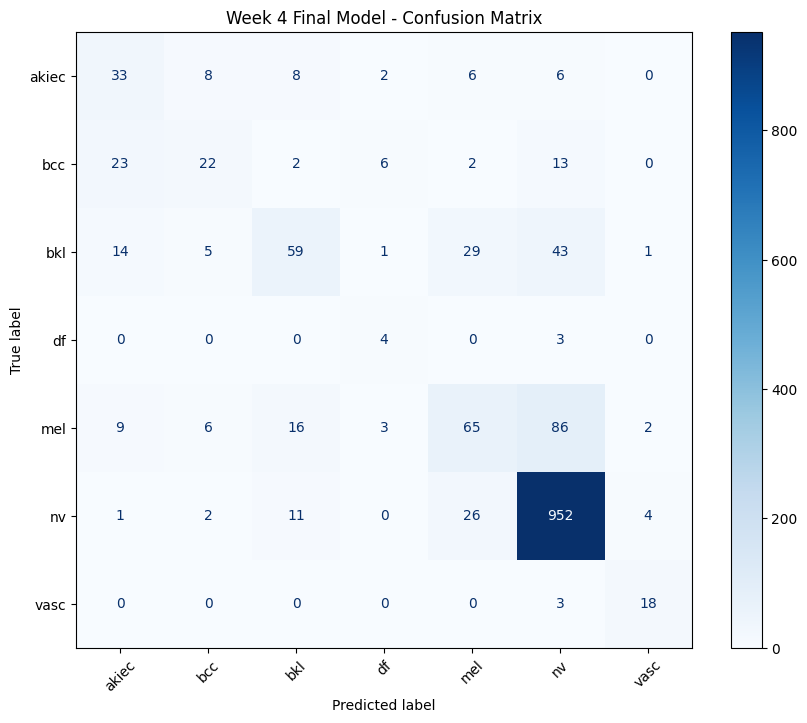

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_week4 = confusion_matrix(y_week4_true, y_week4_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_week4,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("Week 4 Final Model - Confusion Matrix")
plt.xticks(rotation=45)
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: Mountpoint must not already contain files

In [ ]:
import os
import shutil

save_folder = "/content/drive/MyDrive/Skin_Disease_Project"

os.makedirs(save_folder, exist_ok=True)

shutil.copy(
    "week4_improved_model.keras",
    save_folder
)

print("Model saved successfully!")

FileNotFoundError: [Errno 2] No such file or directory: 'week4_improved_model.keras'

In [ ]:
model_path = "/content/drive/MyDrive/Skin_Disease_Project/week4_improved_model.keras"

print("Model exists:", os.path.exists(model_path))

Model exists: True


In [ ]:
import json

project_info = {
    "class_names": class_names,
    "class_mapping": {
        "akiec": 0,
        "bcc": 1,
        "bkl": 2,
        "df": 3,
        "mel": 4,
        "nv": 5,
        "vasc": 6
    },
    "image_size": [224, 224],
    "model_name": "EfficientNetB0",
    "test_accuracy": 0.7718
}

info_path = "/content/drive/MyDrive/Skin_Disease_Project/project_info.json"

with open(info_path, "w") as f:
    json.dump(project_info, f, indent=4)

print("Project information saved successfully!")
print(project_info)

NameError: name 'class_names' is not defined

In [ ]:
import tensorflow as tf

MODEL_PATH = "/content/week4_improved_model.keras"

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully!")
print("Model input shape:", model.input_shape)

Model loaded successfully!
Model input shape: (None, 224, 224, 3)


In [ ]:
from google.colab import files
from PIL import Image
import io

uploaded = files.upload()

# Get the uploaded filename
filename = next(iter(uploaded))

# Open the image
image = Image.open(io.BytesIO(uploaded[filename])).convert("RGB")

print("Image uploaded successfully!")
print("Filename:", filename)
print("Original image size:", image.size)

Saving test4.jpg to test4.jpg
Image uploaded successfully!
Filename: test4.jpg
Original image size: (500, 333)


Prepared image shape: (1, 224, 224, 3)
Pixel range: 5.0 to 255.0


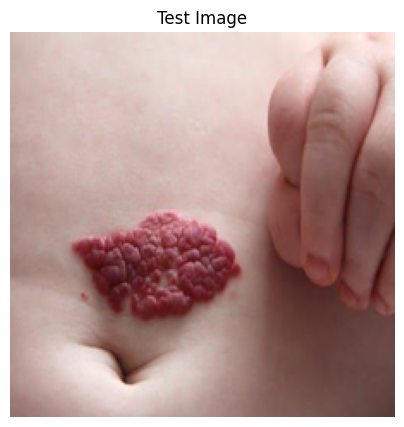

In [ ]:
import numpy as np
import tensorflow as tf
from PIL import Image
import matplotlib.pyplot as plt

# Load the uploaded image
image = Image.open(filename).convert("RGB")

# Resize to model input size
image_resized = image.resize((224, 224))

# Convert to NumPy array
image_array = np.array(image_resized).astype("float32")

# Add batch dimension
input_image = np.expand_dims(image_array, axis=0)

print("Prepared image shape:", input_image.shape)
print("Pixel range:", input_image.min(), "to", input_image.max())

# Display the image
plt.figure(figsize=(5, 5))
plt.imshow(image_resized)
plt.axis("off")
plt.title("Test Image")
plt.show()

In [ ]:
class_names = [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc"
]

print("Class names:", class_names)

Class names: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


In [ ]:
# Make prediction
predictions = model.predict(input_image, verbose=0)

# Get probabilities
probabilities = predictions[0]

# Find predicted class
predicted_index = np.argmax(probabilities)
predicted_class = class_names[predicted_index]
confidence = probabilities[predicted_index] * 100

print("Predicted class:", predicted_class)
print("Confidence:", f"{confidence:.2f}%")

Predicted class: vasc
Confidence: 69.44%


In [ ]:
disease_names = {
    "akiec": "Actinic keratoses",
    "bcc": "Basal cell carcinoma",
    "bkl": "Benign keratosis-like lesions",
    "df": "Dermatofibroma",
    "mel": "Melanoma",
    "nv": "Melanocytic nevi",
    "vasc": "Vascular lesions"
}

predicted_disease = disease_names[predicted_class]

print("=" * 45)
print("       SKIN DISEASE PREDICTION")
print("=" * 45)
print("Predicted class :", predicted_class)
print("Disease         :", predicted_disease)
print("Confidence      :", f"{confidence:.2f}%")
print("=" * 45)
print("Note: This is an AI model prediction,")
print("not a medical diagnosis.")

       SKIN DISEASE PREDICTION
Predicted class : vasc
Disease         : Vascular lesions
Confidence      : 69.44%
Note: This is an AI model prediction,
not a medical diagnosis.


In [ ]:
# Show probability for every disease
print("\nAll class probabilities:")
print("-" * 45)

for i, class_name in enumerate(class_names):
    print(f"{disease_names[class_name]:35s}: {probabilities[i] * 100:.2f}%")


All class probabilities:
---------------------------------------------
Actinic keratoses                  : 6.27%
Basal cell carcinoma               : 1.19%
Benign keratosis-like lesions      : 9.38%
Dermatofibroma                     : 1.11%
Melanoma                           : 8.52%
Melanocytic nevi                   : 4.10%
Vascular lesions                   : 69.44%


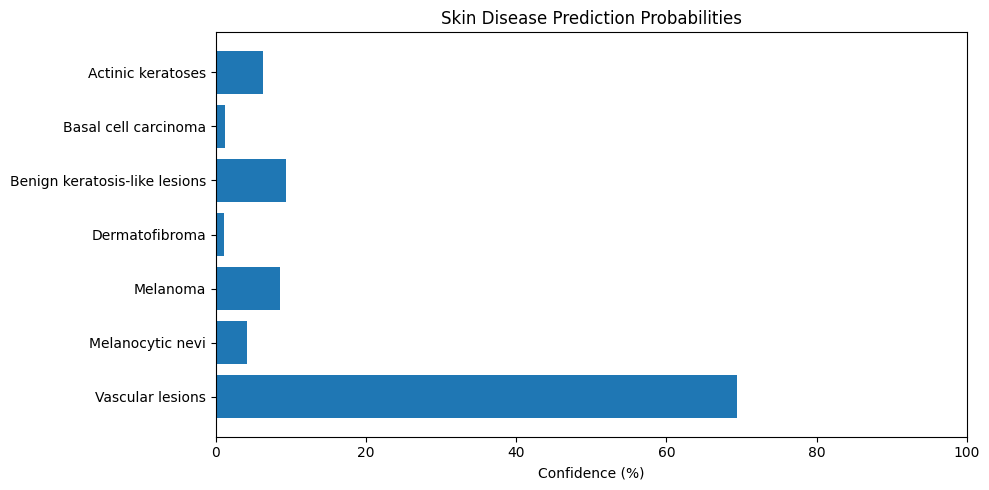

In [ ]:
import matplotlib.pyplot as plt

labels = [disease_names[c] for c in class_names]
percentages = probabilities * 100

plt.figure(figsize=(10, 5))
plt.barh(labels, percentages)
plt.xlabel("Confidence (%)")
plt.title("Skin Disease Prediction Probabilities")
plt.gca().invert_yaxis()
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

In [ ]:
def predict_skin_image(image_path):
    from PIL import Image
    import numpy as np
    import matplotlib.pyplot as plt

    # Load image
    image = Image.open(image_path).convert("RGB")

    # Resize to model input size
    image_resized = image.resize((224, 224))

    # Convert to array
    image_array = np.array(image_resized).astype("float32")

    # Add batch dimension
    input_image = np.expand_dims(image_array, axis=0)

    # Prediction
    predictions = model.predict(input_image, verbose=0)
    probabilities = predictions[0]

    # Get predicted class
    predicted_index = np.argmax(probabilities)
    predicted_class = class_names[predicted_index]
    predicted_disease = disease_names[predicted_class]
    confidence = probabilities[predicted_index] * 100

    # Display image
    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"{predicted_disease}\nConfidence: {confidence:.2f}%")
    plt.show()

    # Display result
    print("=" * 50)
    print("       SKIN DISEASE PREDICTION")
    print("=" * 50)
    print("Predicted class :", predicted_class)
    print("Disease         :", predicted_disease)
    print("Confidence      :", f"{confidence:.2f}%")
    print("=" * 50)
    print("Note: This is an AI model prediction,")
    print("not a medical diagnosis.")

    return predicted_class, predicted_disease, confidence

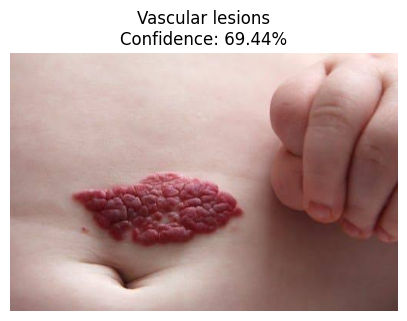

       SKIN DISEASE PREDICTION
Predicted class : vasc
Disease         : Vascular lesions
Confidence      : 69.44%
Note: This is an AI model prediction,
not a medical diagnosis.


('vasc', 'Vascular lesions', np.float32(69.43641))

In [ ]:
predict_skin_image("test4.jpg")